<a href="https://colab.research.google.com/github/Divya4325/Cleaned-Banana-Classification-Detection/blob/main/02_custom_cnn_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!unzip /content/drive/MyDrive/Clean_Banana_dataset.zip -d /content/Clean_Banana_dataset

Streaming output truncated to the last 5000 lines.
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-freshripe-79154a8c-1d0a-11ec-896b-d8c4975e38aa_jpg.rf.ec91229bfa92be00bc14932ffa62d25b.jpg  
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-banana-e48317e6-394a-11ec-beae-d8c4975e38aa_jpg.rf.9679379f6da16d159501aa1e1f270770.jpg  
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-banana-ee3ca35f-394a-11ec-80ab-d8c4975e38aa_jpg.rf.df991bd3bffedada558b36e83cfb940a.jpg  
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-ripe-951db010-1d0a-11ec-b77d-d8c4975e38aa_jpg.rf.99cdda282f3c928fcf14fd191f9ba5c1.jpg  
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-freshripe-787147b6-1d0a-11ec-ae8f-d8c4975e38aa_jpg.rf.74ffca68f00adc435cbff61c4a9f19af.jpg  
  inf

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Data Agumentation**

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import cv2
import matplotlib.pyplot as plt
# Define agumentation Rules
data_gen = ImageDataGenerator(
    rotation_range =20,
    width_shift_range =0.1,
    height_shift_range =0.1,
    zoom_range = 0.2,
    horizontal_flip = True,
    brightness_range =[0.7,1.3],
    fill_mode ='nearest'
)

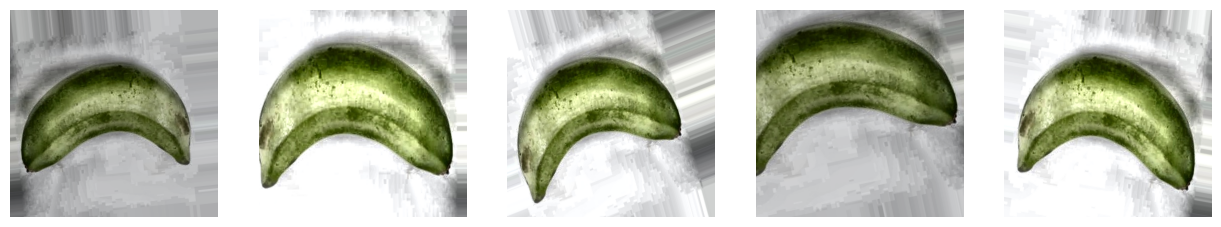

In [ ]:
#Load one sample image
img_path ="/content/Clean_Banana_dataset/content/Clean_Banana_dataset/test/unripe/musa-acuminata-freshunripe-70b033d5-1d0a-11ec-8d75-d8c4975e38aa-Copy_jpg.rf.23dd6a502e46584b9942e58ccb82cf5f.jpg"
img= cv2.imread(img_path)

if img is None:
    raise ValueError(f"Could not load image from {img_path}. Please check the file path and format.")

img = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
img = img.reshape((1,) + img.shape)

# Generate Augmented version
fig,axes = plt.subplots(1,5,figsize =(15.5, 5))
i = 0
for batch in data_gen.flow(img, batch_size =1):
  axes[i].imshow(batch[0].astype('uint8'))
  axes[i].axis('off')
  i +=1
  if i == 5:
    break
plt.show()

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Augmentation for train
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.7, 1.3],
    fill_mode='nearest'
)

# Rescale only for validation
valid_datagen = ImageDataGenerator(rescale=1./255)

# Rescale only for test
test_datagen = ImageDataGenerator(rescale=1./255)

# Paths
train_path = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/train"
valid_path = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/valid"
test_path  = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/test"

# Generators
train_gen = train_datagen.flow_from_directory(
    train_path,
    target_size=(416,416),
    batch_size=32,
    class_mode='categorical'
)

valid_gen = valid_datagen.flow_from_directory(
    valid_path,
    target_size=(416,416),
    batch_size=32,
    class_mode='categorical'
)

test_gen = test_datagen.flow_from_directory(
    test_path,
    target_size=(416,416),
    batch_size=32,
    class_mode='categorical',
    shuffle=False   # keep order for evaluation
)

Found 8923 images belonging to 4 classes.
Found 1123 images belonging to 4 classes.
Found 562 images belonging to 4 classes.


# **CNN Building Architecture**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.mixed_precision import set_global_policy
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [ ]:
set_global_policy('mixed_float16')
model = Sequential([
    Conv2D(16,(3,3), activation='relu', input_shape =(416,416,3)),
    MaxPooling2D(pool_size=(2,2)),

    Conv2D(32,(3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),

    Conv2D(64,(3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),

    Flatten(),
    Dense(64, activation= 'relu'),
    Dropout(0.3),
    Dense(train_gen.num_classes, activation= 'softmax')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Step 2.Compile Model
model.compile(
    optimizer ='adam',
    loss ='categorical_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
callbacks =[
    EarlyStopping(monitor='val_loss',patience =3, restore_best_weights= True),
    ReduceLROnPlateau(monitor ='val_loss',factor =0.2, patience =2, min_lr=1e-6)
]
history =model.fit(
    train_gen,
    validation_data= valid_gen,
    epochs =20,
    batch_size =32,
    callbacks=callbacks
)

Epoch 1/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 485s 2s/step - accuracy: 0.6431 - loss: 1.3180 - val_accuracy: 0.8459 - val_loss: 0.4085 - learning_rate: 0.0010
Epoch 2/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 459s 2s/step - accuracy: 0.8079 - loss: 0.5136 - val_accuracy: 0.7943 - val_loss: 0.5341 - learning_rate: 0.0010
Epoch 3/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 428s 2s/step - accuracy: 0.8341 - loss: 0.4471 - val_accuracy: 0.7996 - val_loss: 0.4854 - learning_rate: 0.0010
Epoch 4/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 435s 2s/step - accuracy: 0.8851 - loss: 0.3208 - val_accuracy: 0.8664 - val_loss: 0.3306 - learning_rate: 2.0000e-04
Epoch 5/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 437s 2s/step - accuracy: 0.8948 - loss: 0.2954 - val_accuracy: 0.8433 - val_loss: 0.3513 - learning_rate: 2.0000e-04
Epoch 6/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 427s 2s/step - accuracy: 0.8967 - loss: 0.2879 - val_accuracy: 0.8477 - val_loss: 0.3523 - learning_rate: 2.0000e-04
Epoch 7/20
279/279 ━━━━━━━━━━━━━━━━━━━━ 416s 1s/step - accuracy: 0.907

In [ ]:
model.save('/content/drive/MyDrive/cnn_model.h5') #Don't run this again

In [ ]:
from google.colab import files
files.download("/content/drive/MyDrive/cnn_model.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Accuracy Graph**

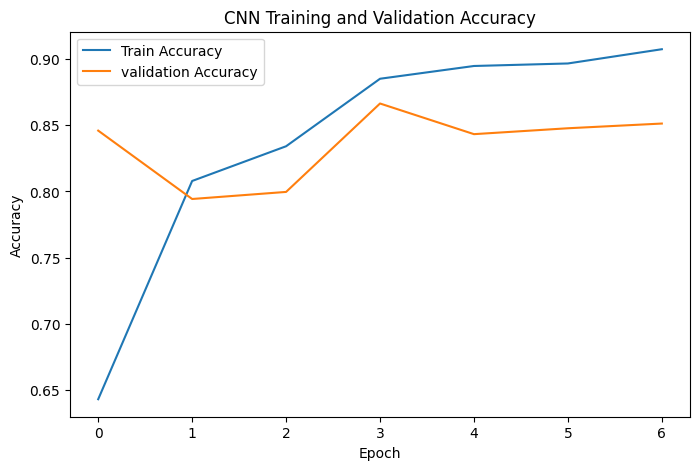

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'],label='Train Accuracy')
plt.plot(history.history['val_accuracy'],label='validation Accuracy')
plt.title('CNN Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig("/content/drive/MyDrive/cnn_accuracy_graph.png",dpi=300,bbox_inches="tight")
plt.show()

**Loss Graph**

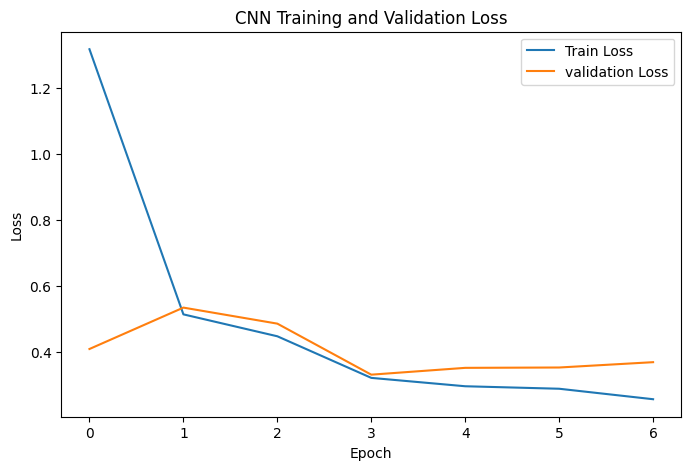

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'],label='Train Loss')
plt.plot(history.history['val_loss'],label='validation Loss')
plt.title('CNN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.savefig("/content/drive/MyDrive/loss_graph.png",dpi=300,bbox_inches="tight")
plt.show()